In [ ]:

###NAME: Fahim Shahriar Ahmed



In [ ]:
###Loading dataset

###libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


df = pd.read_csv('/content/sample_data/adult income dataset.csv')

###Displaying first few rows
df.head(3)

,Age,Workclass,Final Weight,Education,Education Number of Years,Marital-status,Occupation,Relationship,Race,Sex,Capital-gain,Capital-loss,Hours-per-week,Native-country,target
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K


In [ ]:
### rows and cols(features)
features = df.shape
print("Rows: ", features[0])
print("Columns: ", features[1])
print("We have", features[1]-1, "features")
print("This is a Binary classification problem, as we are predicting 2 lebels from the features.")
print(set(df.dtypes))

Rows:  48842
Columns:  15
We have 14 features
This is a Binary classification problem, as we are predicting 2 lebels from the features.
{dtype('int64'), dtype('O')}


In [ ]:
###proti column a kotogulo null value
### We replaced "?" with null value otherwise there was no null values
df.replace('?', np.nan, inplace=True)


df.isnull().sum()


,0
Age,0
Workclass,2799
Final Weight,0
Education,0
Education Number of Years,0
Marital-status,0
Occupation,2809
Relationship,0
Race,0
Sex,0


In [ ]:
###null column er naam
null_cols = df.columns[df.isna().any()].tolist()
print(null_cols)

['Workclass', 'Occupation', 'Native-country']


In [ ]:
###imputing null values with mode
for col in ['Workclass', 'Occupation', 'Native-country']:
    df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
###checking the data types of all cols
df.dtypes

,0
Age,int64
Workclass,object
Final Weight,int64
Education,object
Education Number of Years,int64
Marital-status,object
Occupation,object
Relationship,object
Race,object
Sex,object


In [ ]:
###making categorical(word a likha) values integer/float type
object_cols = df.select_dtypes(include='object').columns.tolist()
print(f"These are the columns who have object dataype \n{object_cols}")

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in object_cols:
  df[col] = le.fit_transform(df[col])

These are the columns who have object dataype 
['Workclass', 'Education', 'Marital-status', 'Occupation', 'Relationship', 'Race', 'Sex', 'Native-country', 'target']


In [ ]:
###after converting to integer
df.dtypes

,0
Age,int64
Workclass,int64
Final Weight,int64
Education,int64
Education Number of Years,int64
Marital-status,int64
Occupation,int64
Relationship,int64
Race,int64
Sex,int64


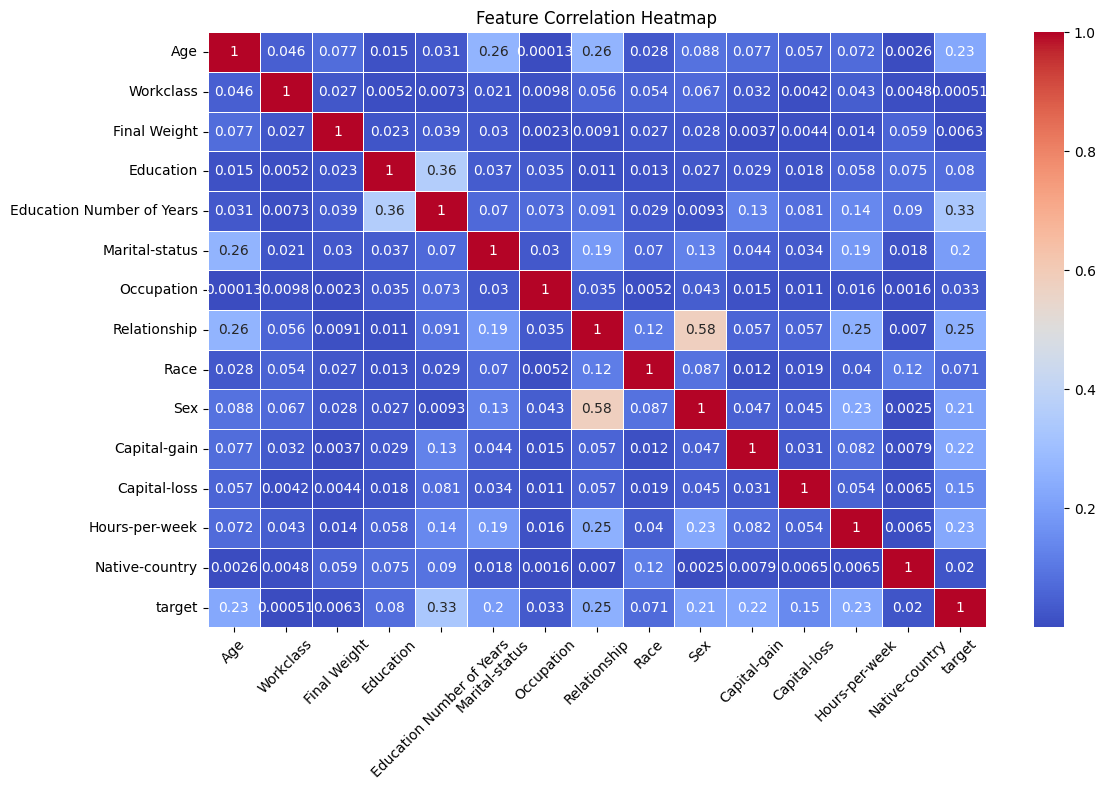

No highly correlated features


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

correlation_matrix = df.corr().abs()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Find highly correlated features (threshold > 0.85)
upper = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
high_corr_pairs = [
    (col1, col2, upper.loc[col2, col1])
    for col1 in upper.columns
    for col2 in upper.index
    if upper.loc[col2, col1] > 0.85
]

# Print result
if not high_corr_pairs:
    print("No highly correlated features")
else:
    print("Highly correlated features (correlation > 0.85):")
    for col1, col2, value in high_corr_pairs:
        print(f"{col1} and {col2} => Correlation: {value:.2f}")

In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target variable
X = df.drop('target', axis=1)
y = df['target']
#Random stater what?
# Split the dataset with stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    stratify=y,           # maintain class distribution
    random_state=42       # for reproducibility
)

# Print shape to verify
print("Train set size:", X_train.shape)
print("Test set size:", X_test.shape)

# Optional: Show class balance
print("\nClass distribution in training set:")
print(y_train.value_counts(normalize=True))

print("\nClass distribution in test set:")
print(y_test.value_counts(normalize=True))

Train set size: (34189, 14)
Test set size: (14653, 14)

Class distribution in training set:
target
0    0.760713
1    0.239287
Name: proportion, dtype: float64

Class distribution in test set:
target
0    0.760732
1    0.239268
Name: proportion, dtype: float64


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)
print("KNN Accuracy:", accuracy_score(y_test, knn_pred))
print("\nKNN Classification Report:\n", classification_report(y_test, knn_pred))

KNN Accuracy: 0.7758820719306626

KNN Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.92      0.86     11147
           1       0.55      0.32      0.41      3506

    accuracy                           0.78     14653
   macro avg       0.68      0.62      0.63     14653
weighted avg       0.75      0.78      0.75     14653



In [ ]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, tree_pred))
print("\nDecision Tree Classification Report:\n", classification_report(y_test, tree_pred))

Decision Tree Accuracy: 0.8179894902067836

Decision Tree Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.88      0.88     11147
           1       0.62      0.63      0.62      3506

    accuracy                           0.82     14653
   macro avg       0.75      0.75      0.75     14653
weighted avg       0.82      0.82      0.82     14653



In [ ]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)

# Evaluation
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Logistic Regression Accuracy: 0.8097317955367501

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.94      0.88     11147
           1       0.67      0.40      0.50      3506

    accuracy                           0.81     14653
   macro avg       0.75      0.67      0.69     14653
weighted avg       0.79      0.81      0.79     14653



/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
# Neural Network (Binary Classification)

from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
model = Sequential()
model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='sigmoid'))  # Binary classification output

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=10, batch_size=32, verbose=1)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1069/1069 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6754 - loss: 434.5234
Epoch 2/10
1069/1069 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6798 - loss: 252.2554
Epoch 3/10
1069/1069 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6765 - loss: 210.5871
Epoch 4/10
1069/1069 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6901 - loss: 175.9942
Epoch 5/10
1069/1069 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6926 - loss: 142.1489
Epoch 6/10
1069/1069 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6877 - loss: 115.8680
Epoch 7/10
1069/1069 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6849 - loss: 137.9193
Epoch 8/10
1069/1069 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6892 - loss: 87.5665
Epoch 9/10
1069/1069 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6879 - loss: 79.7327
Epoch 10/10
1069/1069 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6928 - loss: 86.1611


458/458 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
458/458 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


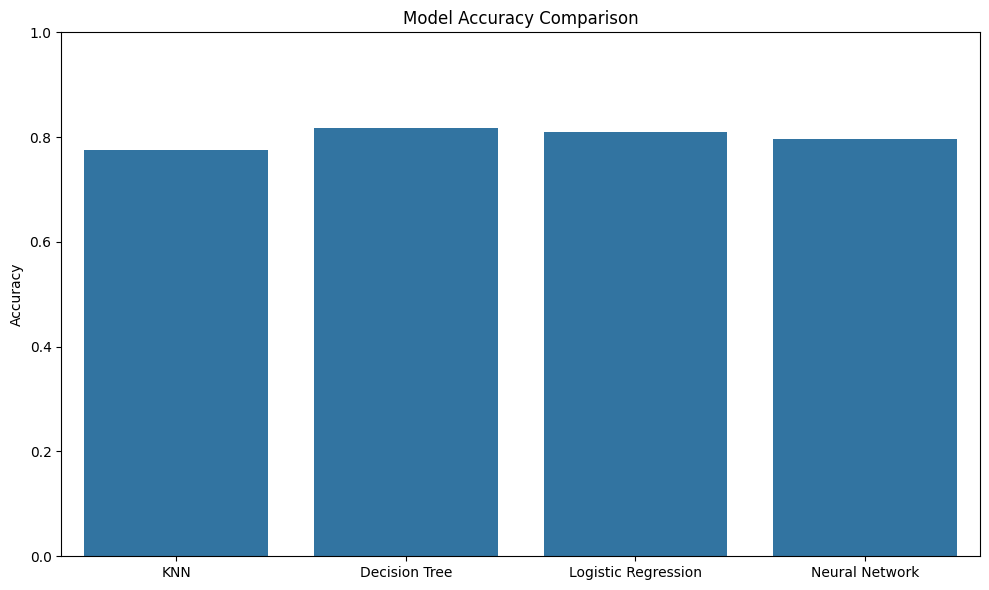

In [ ]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Collect predictions and probabilities
y_pred_knn = knn.predict(X_test)
y_prob_knn = knn.predict_proba(X_test)[:, 1]

y_pred_tree = tree.predict(X_test)
y_prob_tree = tree.predict_proba(X_test)[:, 1]

y_pred_logreg = logreg.predict(X_test)
y_prob_logreg = logreg.predict_proba(X_test)[:, 1]

y_pred_nn = (model.predict(X_test) > 0.5).astype(int).flatten()
y_prob_nn = model.predict(X_test).flatten()

# Store metrics for all models
models = ["KNN", "Decision Tree", "Logistic Regression", "Neural Network"]
accuracies = [
    accuracy_score(y_test, y_pred_knn),
    accuracy_score(y_test, y_pred_tree),
    accuracy_score(y_test, y_pred_logreg),
    accuracy_score(y_test, y_pred_nn)
]
precisions = [
    precision_score(y_test, y_pred_knn),
    precision_score(y_test, y_pred_tree),
    precision_score(y_test, y_pred_logreg),
    precision_score(y_test, y_pred_nn)
]
recalls = [
    recall_score(y_test, y_pred_knn),
    recall_score(y_test, y_pred_tree),
    recall_score(y_test, y_pred_logreg),
    recall_score(y_test, y_pred_nn)
]
aucs = [
    roc_auc_score(y_test, y_prob_knn),
    roc_auc_score(y_test, y_prob_tree),
    roc_auc_score(y_test, y_prob_logreg),
    roc_auc_score(y_test, y_prob_nn)
]



### 1. Accuracy Comparison Bar Chart

plt.figure(figsize=(10, 6))
sns.barplot(x=models, y=accuracies)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


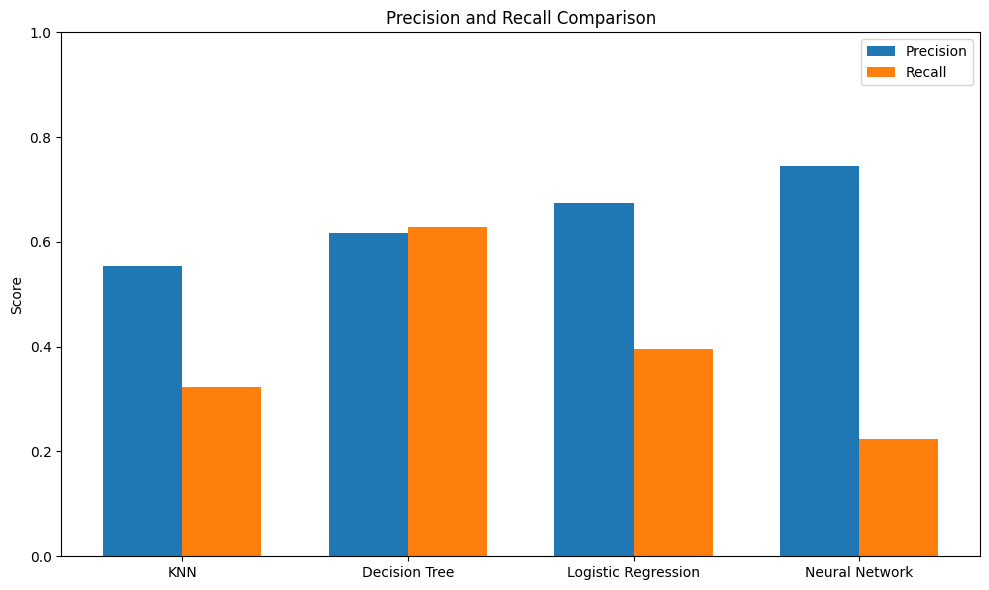

In [ ]:
### 2. Precision & Recall Comparison

x = np.arange(len(models))
width = 0.35
plt.figure(figsize=(10, 6))
plt.bar(x - width/2, precisions, width, label='Precision')
plt.bar(x + width/2, recalls, width, label='Recall')
plt.xticks(x, models)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Precision and Recall Comparison")
plt.legend()
plt.tight_layout()
plt.show()


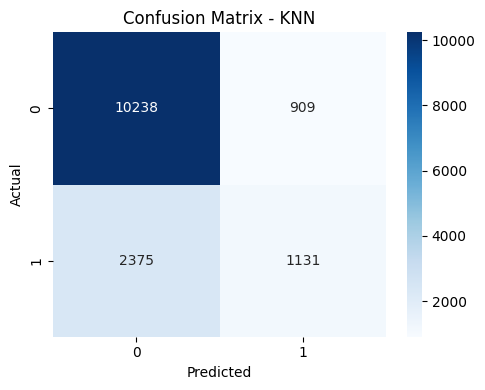

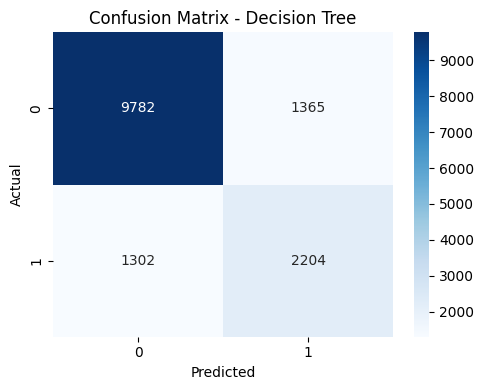

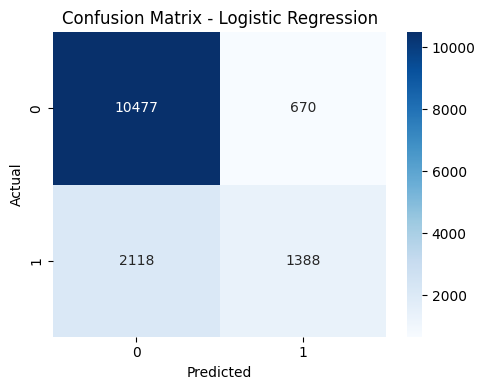

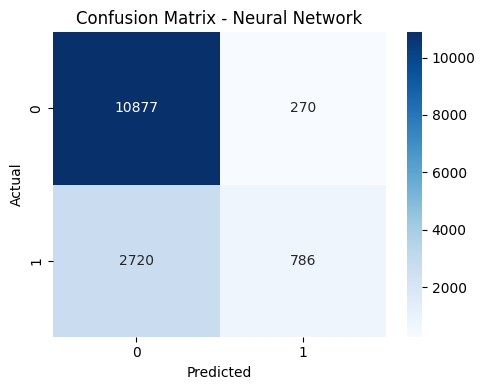

In [ ]:

### 3. Confusion Matrices

predictions = [y_pred_knn, y_pred_tree, y_pred_logreg, y_pred_nn]
for i, pred in enumerate(predictions):
    cm = confusion_matrix(y_test, pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - {models[i]}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


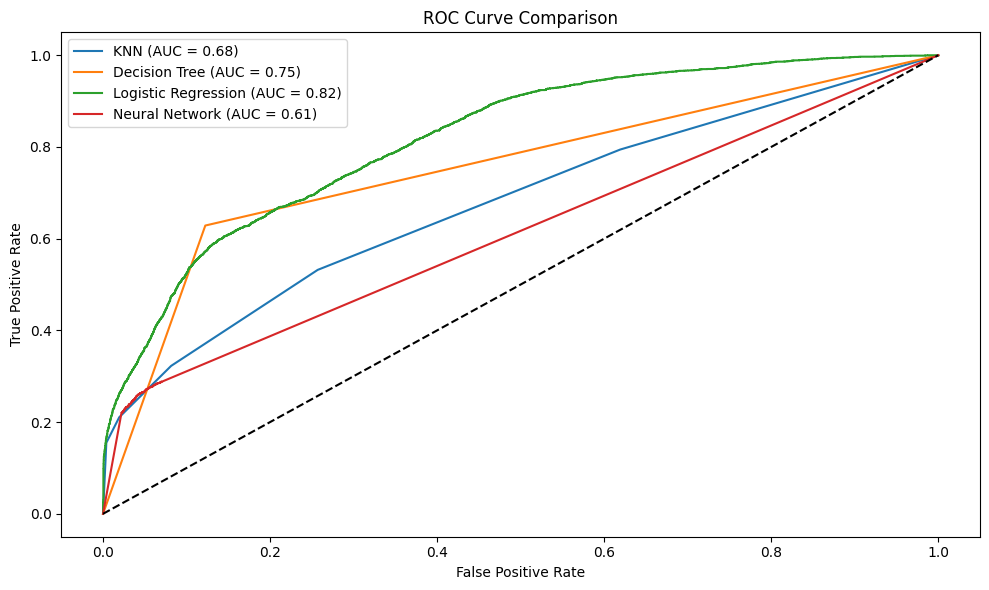

In [ ]:
### 4. ROC Curve & AUC

probs = [y_prob_knn, y_prob_tree, y_prob_logreg, y_prob_nn]
plt.figure(figsize=(10, 6))
for i, prob in enumerate(probs):
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{models[i]} (AUC = {aucs[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()